# 04 — Exhaustion in T and NK cells

The hard constraint first: **513 CD8 T cells** in the whole single-cell object, a median of
~14 per sample, some samples with 1-3. Pdcd1 is detected in 19% of CD8 cells, Havcr2 15%, Lag3
8%, Tigit 14%. So:

* the **sample is the unit** — per-sample scores and detection fractions, samples with >= 8
  cells of the type; tested with the exact-relabelling engine of `03`;
* a **binomial mixed model** per marker (`detected ~ contrast + (1 | sample)`, variational Bayes,
  `statsmodels.BinomialBayesMixedGLM`) is the cell-level cross-check — with 2-3 samples a side the
  random-effect variance is poorly estimated, so it is read as supporting evidence only;
* every marker gets a **minimum detectable effect** (percentage points of detection at n = 3 v 3,
  80% power), so "no effect" and "could not have seen it" are kept apart;
* the **receiving side is well powered**: checkpoint ligands on macrophages / DC / tumour
  (from `02`), the signals that drive exhaustion.

Modules (curated; no exhaustion set exists in these GMTs): inhibitory receptors (`Pdcd1,
Havcr2, Lag3, Tigit, Ctla4, Cd160, Cd244a, Entpd1`), exhaustion TFs (`Tox, Tox2, Nr4a1-3, Batf,
Irf4`), progenitor-exhausted (`Tcf7, Slamf6, Xcl1, Id3, Cxcr5`) and terminal-exhausted (`Havcr2,
Entpd1, Cd38, Cd101, Gzmb`). The progenitor module is reported **with and without `Xcl1`**
(a chemokine), and the effector module with and without `Ccl5`.

Last, the **Cd44 caveat**: Cd44 is the SPP1 receptor, but on T cells it is also the classic
antigen-experience / activation marker. If Cd44 tracks effector or exhaustion state *within*
CD8/NK cells, then "SPP1–CD44-high" and "cytotoxic-high" are not independent readouts in space.

## 1. Config and cells

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

pd.set_option("display.width", 280); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 400)
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
OUT = PROJ/"results/mhc_cytotox"; FIG = OUT/"figures"
MIN_CELLS_EXH, SEED = 8, 0
ARM_ORDER = ["NoTx", "CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"]
COL = {"NoTx": "#9e9e9e", "CyPSCA": "#3b6ea5", "CyT72": "#7fa7d1", "RTCyPSCA": "#d1495b", "RTCyT72": "#ec9a9a"}

CAT = json.load(open(OUT/"programs.json")); PROGRAMS = CAT["programs"]
cp = pd.read_parquet(OUT/"cell_panel.parquet")
POP = {"CD8_T": cp.ct2 == "CD8_T", "NK": cp.ct2 == "NK", "NKT": cp.ct2 == "NKT",
       "CD4_T+Treg": cp.ct2.isin(["CD4_T", "Treg"]), "T_all": cp.ct2.isin(["CD8_T", "CD4_T", "Treg", "NKT"])}
print({k: int(v.sum()) for k, v in POP.items()})

MODS = ["exh_inhibitory_receptors", "exh_TFs", "exh_progenitor", "exh_progenitor_noXcl1", "exh_terminal",
        "cyto_effector", "cyto_effector_noCcl5"]
IR = PROGRAMS["exh_inhibitory_receptors"]["genes"]
MARKERS = [g for g in ["Pdcd1", "Havcr2", "Lag3", "Tigit", "Ctla4", "Tox", "Entpd1", "Tcf7", "Slamf6",
                       "Gzmb", "Prf1", "Nkg7", "Ifng", "Cd44"] if g in cp]


def lognorm(d, genes_):
    return np.log1p(d[genes_].div(d.total_counts, axis=0) * 1e4)

{'CD8_T': 513, 'NK': 1008, 'NKT': 106, 'CD4_T+Treg': 164, 'T_all': 783}


## 2. Per-cell module scores and co-expression, summarised per sample

In [2]:
rows = []
for pop, m in POP.items():
    d = cp[m.values]
    sc = pd.DataFrame({k: lognorm(d, [g for g in PROGRAMS[k]["genes"] if g in d]).mean(1) for k in MODS},
                      index=d.index)
    det = (d[IR] > 0)
    sc["n_IR"] = det.sum(1)
    sc["IR_ge2"] = (det.sum(1) >= 2).astype(float)
    sc["Tox_Pdcd1"] = ((d["Tox"] > 0) & (d["Pdcd1"] > 0)).astype(float)
    for g in MARKERS: sc[f"{g}+"] = (d[g] > 0).astype(float)
    sc["Cd44_ln"] = lognorm(d, ["Cd44"])["Cd44"]
    full = sc.join(d[["sample", "arm", "site", "mouse", "RT", "cart"]])
    full["pop"] = pop
    rows.append(full)
CELLS = pd.concat(rows)
CELLS.to_parquet(OUT/"exhaustion_cell_scores.parquet")

SUMCOLS = MODS + ["n_IR", "IR_ge2", "Tox_Pdcd1"] + [f"{g}+" for g in MARKERS]
SMP = (CELLS.groupby(["pop", "sample"]).agg(n=("arm", "size"), arm=("arm", "first"), site=("site", "first"),
                                            mouse=("mouse", "first"), **{c: (c, "mean") for c in SUMCOLS})
          .reset_index())
SMP["term_minus_prog"] = SMP.exh_terminal - SMP.exh_progenitor_noXcl1
SMP.to_csv(OUT/"exhaustion_per_sample.csv", index=False)
use = SMP[SMP.n >= MIN_CELLS_EXH]
print(f"usable samples (>= {MIN_CELLS_EXH} cells) per population and condition:")
print(use.assign(cond=use.arm + "_Tu" + use.site.astype(str))
         .pivot_table(index="pop", columns="cond", values="n", aggfunc="count").fillna(0).astype(int).to_string())
print("\nper-condition means, CD8_T (samples with >= 8 cells)")
cd8 = use[use["pop"] == "CD8_T"].assign(cond=lambda d: d.arm + "_Tu" + d.site.astype(str))
print(cd8.groupby("cond")[["n", "IR_ge2", "Tox_Pdcd1", "Pdcd1+", "Havcr2+", "Tox+", "Tcf7+", "Gzmb+",
                           "exh_inhibitory_receptors", "exh_progenitor_noXcl1", "exh_terminal", "term_minus_prog"]]
         .mean().round(3).to_string())

usable samples (>= 8 cells) per population and condition:
cond        CyPSCA_Tu1  CyPSCA_Tu2  CyT72_Tu1  CyT72_Tu2  NoTx_Tu1  NoTx_Tu2  RTCyPSCA_Tu1  RTCyPSCA_Tu2  RTCyT72_Tu1  RTCyT72_Tu2
pop                                                                                                                               
CD4_T+Treg           2           0          1          0         0         1             1             0            2            0
CD8_T                3           1          2          1         0         1             2             2            3            3
NK                   3           2          2          3         2         0             3             3            3            3
NKT                  1           0          0          0         0         0             1             0            2            0
T_all                3           2          2          2         3         2             3             3            3            3

per-condition means, CD8

## 3. Sample-level contrasts — exact relabelling (the primary test)

In [3]:
def cell_null(v, meta, A, B, site):
    idx = meta.index[meta.arm.isin([A, B]) & (meta.site == site)]
    idx = [i for i in idx if np.isfinite(v.get(i, np.nan))]
    obs = (meta.loc[idx, "arm"] == A).values; k, n = int(obs.sum()), len(idx)
    if k < 2 or n - k < 2: return None
    x = v.loc[idx].values
    out = [x[obs].mean() - x[~obs].mean()]
    for c in itertools.combinations(range(n), k):
        msk = np.isin(np.arange(n), c)
        if (msk == obs).all(): continue
        out.append(x[msk].mean() - x[~msk].mean())
    return np.array(out)


def combine(a, b, how):
    return ((a[:, None] + b[None, :]) / 2 if how == "mean" else a[:, None] - b[None, :]).ravel()


def p2(a): return float((np.abs(a) >= abs(a[0]) - 1e-12).mean())


EFF = {"PSCA": [("nonRT", "CyPSCA", "CyT72"), ("RT", "RTCyPSCA", "RTCyT72")],
       "direct RT": [("PSCA", "RTCyPSCA", "CyPSCA", 1), ("TAG72", "RTCyT72", "CyT72", 1)],
       "indirect RT": [("PSCA", "RTCyPSCA", "CyPSCA", 2), ("TAG72", "RTCyT72", "CyT72", 2)]}
TESTCOLS = ["IR_ge2", "Tox_Pdcd1", "Pdcd1+", "Havcr2+", "Lag3+", "Tigit+", "Tox+", "Entpd1+", "Tcf7+",
            "Gzmb+", "Prf1+", "exh_inhibitory_receptors", "exh_TFs", "exh_progenitor", "exh_progenitor_noXcl1",
            "exh_terminal", "term_minus_prog", "cyto_effector", "cyto_effector_noCcl5"]
res = []
for pop in ["CD8_T", "NK", "T_all"]:
    d = use[use["pop"] == pop].set_index("sample")
    meta = d[["arm", "site", "mouse"]]
    sdw = d[d.arm != "NoTx"].groupby(["arm", "site"])[TESTCOLS].var().mean().pow(0.5)
    for col in TESTCOLS:
        v = d[col]
        for eff, strata in EFF.items():
            nulls = {}
            for st in strata:
                if eff == "PSCA":
                    parts = [n_ for s in (1, 2) if (n_ := cell_null(v, meta, st[1], st[2], s)) is not None]
                    if parts:
                        nulls[st[0]] = parts[0] if len(parts) == 1 else combine(parts[0], parts[1], "mean")
                else:
                    n_ = cell_null(v, meta, st[1], st[2], st[3])
                    if n_ is not None: nulls[st[0]] = n_
            r = dict(pop=pop, measure=col, effect=eff)
            for k, n_ in nulls.items():
                r[f"d_{k}"] = n_[0]; r[f"p_{k}"] = p2(n_)
            if len(nulls) == 2:
                a, b = list(nulls.values())
                mn = combine(a, b, "mean"); it = combine(b, a, "diff") if eff == "PSCA" else combine(a, b, "diff")
                r.update(main=mn[0], p_main=p2(mn), interaction=it[0], p_inter=p2(it),
                         sign_agree=bool(np.sign(a[0]) == np.sign(b[0])), sd_within=sdw[col])
            res.append(r)
EX = pd.DataFrame(res)
EX.to_csv(OUT/"exhaustion_sample_contrasts.csv", index=False)
show = EX[EX["pop"] == "CD8_T"]
print("CD8_T — sample-level contrasts (fractions are 0-1; scores are mean log-norm)")
print(show[["measure", "effect", "d_nonRT", "d_RT", "d_PSCA", "d_TAG72", "main", "p_main", "sign_agree",
            "interaction", "p_inter"]].round(3).to_string(index=False))

CD8_T — sample-level contrasts (fractions are 0-1; scores are mean log-norm)
                 measure      effect  d_nonRT   d_RT  d_PSCA  d_TAG72   main  p_main sign_agree  interaction  p_inter
                  IR_ge2        PSCA   -0.025 -0.091     NaN      NaN -0.058   0.448       True       -0.066    0.679
                  IR_ge2   direct RT      NaN    NaN   0.157    0.190  0.173   0.030       True       -0.033    0.920
                  IR_ge2 indirect RT      NaN    NaN     NaN      NaN    NaN     NaN        NaN          NaN      NaN
               Tox_Pdcd1        PSCA    0.139  0.026     NaN      NaN  0.083   0.052       True       -0.113    0.234
               Tox_Pdcd1   direct RT      NaN    NaN  -0.119   -0.001 -0.060   0.200       True       -0.118    0.220
               Tox_Pdcd1 indirect RT      NaN    NaN     NaN      NaN    NaN     NaN        NaN          NaN      NaN
                  Pdcd1+        PSCA    0.139  0.035     NaN      NaN  0.087   0.062       True  

## 4. Minimum detectable effect

From the pooled within-condition SD of each sample-level measure: the smallest difference a
two-sided test at n = 3 v 3 would detect with 80% power. Shown next to the measure's mean, so a
null can be read as "absent" only when the MDE is small relative to the mean.

In [4]:
mde = []
df = 4
k_ = (stats.t.ppf(0.975, df) + stats.t.ppf(0.80, df)) * np.sqrt(2 / 3)
for pop in ["CD8_T", "NK", "T_all"]:
    d = use[(use["pop"] == pop) & (use.arm != "NoTx")]
    sdp = d.groupby(["arm", "site"])[TESTCOLS].var().mean().pow(0.5)
    for col in TESTCOLS:
        mde.append(dict(pop=pop, measure=col, mean=d[col].mean(), sd_within=sdp[col], MDE=k_ * sdp[col],
                        MDE_rel=k_ * sdp[col] / max(abs(d[col].mean()), 1e-9)))
MDE = pd.DataFrame(mde)
MDE.to_csv(OUT/"exhaustion_mde.csv", index=False)
print(MDE[MDE["pop"] == "CD8_T"].round(3).to_string(index=False))

  pop                  measure  mean  sd_within   MDE  MDE_rel
CD8_T                   IR_ge2 0.484      0.150 0.454    0.939
CD8_T                Tox_Pdcd1 0.113      0.055 0.166    1.469
CD8_T                   Pdcd1+ 0.200      0.066 0.201    1.003
CD8_T                  Havcr2+ 0.154      0.087 0.264    1.717
CD8_T                    Lag3+ 0.079      0.051 0.154    1.952
CD8_T                   Tigit+ 0.142      0.060 0.181    1.278
CD8_T                     Tox+ 0.503      0.104 0.317    0.629
CD8_T                  Entpd1+ 0.285      0.145 0.440    1.542
CD8_T                    Tcf7+ 0.473      0.095 0.289    0.610
CD8_T                    Gzmb+ 0.582      0.160 0.487    0.836
CD8_T                    Prf1+ 0.118      0.057 0.174    1.480
CD8_T exh_inhibitory_receptors 0.288      0.073 0.220    0.766
CD8_T                  exh_TFs 0.488      0.144 0.436    0.894
CD8_T           exh_progenitor 0.308      0.067 0.202    0.658
CD8_T    exh_progenitor_noXcl1 0.302      0.101 0.306  

## 5. Binomial mixed models — the cell-level cross-check

One model per marker, population and two-arm comparison: `detected ~ A_vs_B + (1 | sample)`.
Reported: posterior mean log-odds, its SD, and the z / two-sided p from those.

In [5]:
COMPS = [("PSCA nonRT Tu1", "CyPSCA", "CyT72", 1), ("PSCA nonRT Tu2", "CyPSCA", "CyT72", 2),
         ("PSCA RT Tu1", "RTCyPSCA", "RTCyT72", 1), ("PSCA RT Tu2", "RTCyPSCA", "RTCyT72", 2),
         ("direct RT PSCA", "RTCyPSCA", "CyPSCA", 1), ("direct RT TAG72", "RTCyT72", "CyT72", 1),
         ("indirect RT PSCA", "RTCyPSCA", "CyPSCA", 2), ("indirect RT TAG72", "RTCyT72", "CyT72", 2)]
GL_MARK = ["Pdcd1+", "Havcr2+", "Lag3+", "Tigit+", "Tox+", "Entpd1+", "Tcf7+", "Gzmb+", "Prf1+", "IR_ge2"]
gl = []
for pop in ["CD8_T", "NK"]:
    C_ = CELLS[CELLS["pop"] == pop]
    for name, A, B, site in COMPS:
        d = C_[C_.arm.isin([A, B]) & (C_.site == site)].copy()
        if d["sample"].nunique() < 4 or d.groupby("arm")["sample"].nunique().min() < 2: continue
        d["x"] = (d.arm == A).astype(float)
        for mk in GL_MARK:
            d["y"] = (d[mk] > 0).astype(float)
            if d.y.sum() < 5 or (1 - d.y).sum() < 5: continue
            try:
                m = BinomialBayesMixedGLM.from_formula("y ~ x", {"sample": "0 + C(sample)"}, d).fit_vb()
                b, s = float(m.fe_mean[1]), float(m.fe_sd[1])
                gl.append(dict(pop=pop, comparison=name, marker=mk, n_cells=len(d),
                               n_samples=d["sample"].nunique(), logodds=b, sd=s, z=b / s,
                               p=2 * (1 - stats.norm.cdf(abs(b / s)))))
            except Exception as e:
                gl.append(dict(pop=pop, comparison=name, marker=mk, n_cells=len(d), error=str(e)[:60]))
GLMM = pd.DataFrame(gl)
GLMM.to_csv(OUT/"exhaustion_glmm.csv", index=False)
print(GLMM[(GLMM["pop"] == "CD8_T")].pivot_table(index="marker", columns="comparison", values="z")
        .round(2).to_string())
print("\n|z| > 2 in CD8_T or NK:")
print(GLMM[GLMM.z.abs() > 2].round(3).to_string(index=False) if "z" in GLMM else "none")

comparison  PSCA RT Tu1  PSCA RT Tu2  PSCA nonRT Tu1  PSCA nonRT Tu2  direct RT PSCA  direct RT TAG72  indirect RT PSCA  indirect RT TAG72
marker                                                                                                                                    
Entpd1+           -0.50        -0.33           -2.99           -0.12            4.87             2.56              0.43               0.60
Gzmb+             -0.44         1.10           -3.23           -0.40            5.72             4.26              1.78              -0.16
Havcr2+            1.07         0.65           -1.68           -1.43            3.69             0.87              0.76              -1.38
IR_ge2            -0.57        -1.16           -1.14            0.97            2.62             3.19             -0.13               2.15
Lag3+              3.48         1.28            0.26             NaN            2.55            -0.47              0.16                NaN
Pdcd1+             1.31    

## 6. The receiving side — checkpoint ligands on myeloid cells, DC and tumour (from `02`)

In [6]:
REPL = pd.read_csv(OUT/"de_panel_replication.csv")
PANEL = pd.read_csv(OUT/"de_panel_genes.csv")
ck = REPL[REPL.panel == "checkpoint"]
print("checkpoint ligands replicated (both strata / both backgrounds):")
print(ck[ck.replicated][["effect", "group", "gene", "baseMean", "lfc_1", "q_1", "lfc_2", "q_2", "loo_flips"]]
        .round(3).to_string(index=False) or "    none")
inter = PANEL[(PANEL.panel == "checkpoint") & PANEL.contrast.isin(["CARxRT", "DiD_PSCA", "DiD_TAG72"])
              & (PANEL.panel_padj < 0.05)]
print("\ncheckpoint ligands with CAR x RT or DiD effects (panel_padj < 0.05):")
print(inter[["contrast", "group", "gene", "baseMean", "log2FoldChange", "panel_padj"]].round(4).to_string(index=False)
      if len(inter) else "    none")
tab = (PANEL[(PANEL.panel == "checkpoint") & PANEL.group.isin(["IFN_stimulated_Mac", "M2_like_Mac", "cDC",
                                                               "Classical_Mono", "Cancer_cell"])
             & PANEL.contrast.isin(["PSCA_nonRT", "PSCA_RT", "directRT_PSCA", "directRT_TAG72",
                                    "indirectRT_PSCA", "indirectRT_TAG72"])]
       .pivot_table(index=["gene", "group"], columns="contrast", values="log2FoldChange"))
print("\ncheckpoint ligand log2FC (rows: gene x source):")
print(tab.round(2).to_string())

checkpoint ligands replicated (both strata / both backgrounds):
effect              group     gene  baseMean  lfc_1   q_1  lfc_2   q_2   loo_flips
  PSCA     Classical_Mono    Cd274  4513.786  2.454 0.000  1.604 0.000 0/11 | 0/12
  PSCA     Classical_Mono  Ceacam1   124.346 -0.604 0.001 -0.407 0.064 0/11 | 0/12
  PSCA     Classical_Mono Pdcd1lg2   124.729  0.803 0.006  0.663 0.004 0/11 | 0/12
  PSCA        Endothelial    Cd274    39.849  2.448 0.102  3.086 0.000   1/5 | 0/7
  PSCA IFN_stimulated_Mac    Cd274  3374.942  2.297 0.000  1.775 0.000 0/11 | 0/12
  PSCA IFN_stimulated_Mac  Ceacam1    60.130 -1.347 0.000 -1.206 0.000 0/11 | 0/12
  PSCA   Intermediate_Mac    Cd274  1218.907  2.328 0.000  1.563 0.000 0/11 | 0/12
  PSCA   Intermediate_Mac  Ceacam1    70.677 -0.610 0.027 -0.557 0.097 0/11 | 0/12
  PSCA        M2_like_Mac    Cd274  5012.290  1.978 0.000  1.478 0.000 0/11 | 0/12
  PSCA        M2_like_Mac Pdcd1lg2   760.383  0.796 0.031  0.929 0.016 0/11 | 0/12
  PSCA        N1_like_N

## 7. The Cd44 caveat — does Cd44 track effector / exhaustion state inside CD8 and NK cells?

Per sample (>= 8 cells): Spearman ρ between per-cell `Cd44` and each module, then the mean ρ
across samples with a one-sample t-test (sample = unit).

In [7]:
cd = []
for pop in ["CD8_T", "NK"]:
    for s, d in CELLS[CELLS["pop"] == pop].groupby("sample"):
        if len(d) < MIN_CELLS_EXH or d.Cd44_ln.std() == 0: continue
        r = dict(pop=pop, sample=s)
        for m in ["cyto_effector_noCcl5", "exh_inhibitory_receptors", "exh_terminal", "exh_progenitor_noXcl1"]:
            r[m] = stats.spearmanr(d.Cd44_ln, d[m]).statistic if d[m].std() > 0 else np.nan
        cd.append(r)
CD = pd.DataFrame(cd)
CD.to_csv(OUT/"cd44_within_cell_correlation.csv", index=False)
cd_sum = []
for pop, d in CD.groupby("pop"):
    for m in ["cyto_effector_noCcl5", "exh_inhibitory_receptors", "exh_terminal", "exh_progenitor_noXcl1"]:
        v = d[m].dropna()
        cd_sum.append(dict(pop=pop, module=m, n_samples=len(v), mean_rho=v.mean(),
                           frac_positive=(v > 0).mean(), p_ttest=stats.ttest_1samp(v, 0).pvalue))
CDS = pd.DataFrame(cd_sum)
print(CDS.round(3).to_string(index=False))

  pop                   module  n_samples  mean_rho  frac_positive  p_ttest
CD8_T     cyto_effector_noCcl5         18     0.095          0.667    0.042
CD8_T exh_inhibitory_receptors         18     0.132          0.722    0.077
CD8_T             exh_terminal         18     0.209          0.722    0.004
CD8_T    exh_progenitor_noXcl1         18    -0.025          0.500    0.661
   NK     cyto_effector_noCcl5         24     0.067          0.583    0.192
   NK exh_inhibitory_receptors         24    -0.063          0.375    0.100
   NK             exh_terminal         24    -0.055          0.333    0.187
   NK    exh_progenitor_noXcl1         24     0.123          0.708    0.008


## 8. Figure — per-sample exhaustion measures, CD8_T

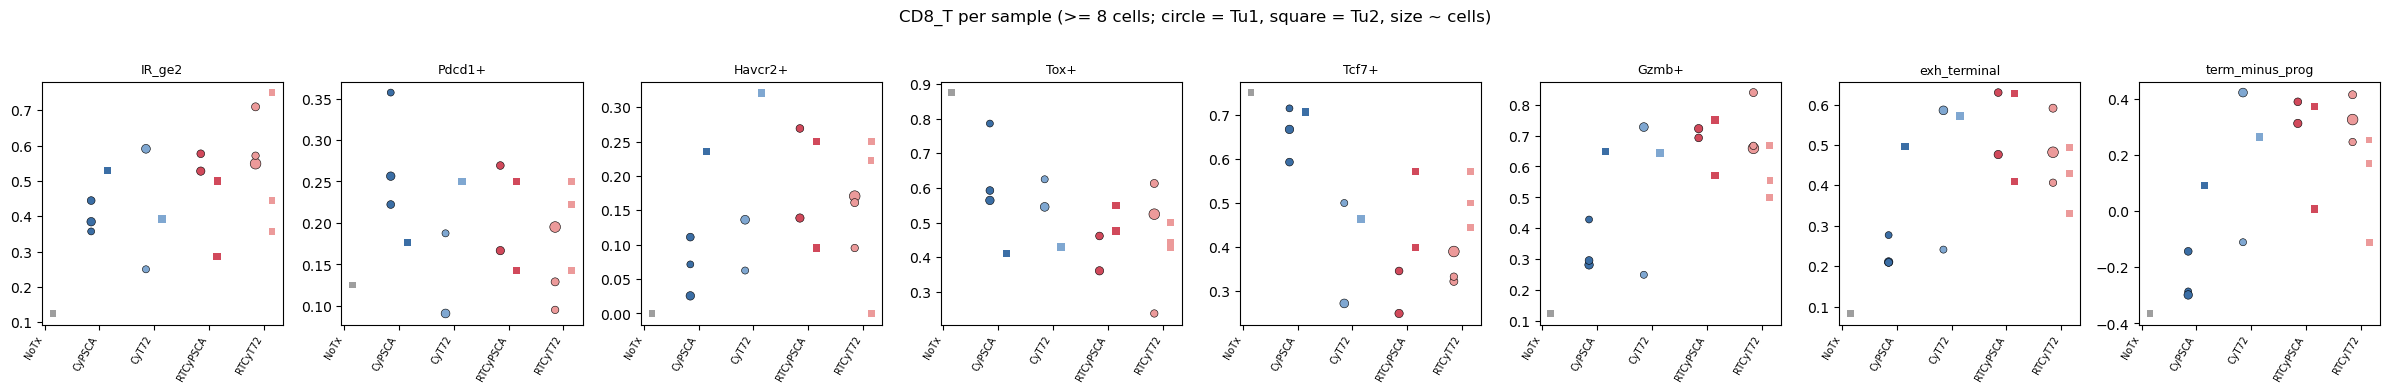

In [8]:
FCOLS = ["IR_ge2", "Pdcd1+", "Havcr2+", "Tox+", "Tcf7+", "Gzmb+", "exh_terminal", "term_minus_prog"]
fig, axes = plt.subplots(1, len(FCOLS), figsize=(3.0*len(FCOLS), 3.8))
for ax, col in zip(axes, FCOLS):
    for i, arm in enumerate(ARM_ORDER):
        for s_, mk in [(1, "o"), (2, "s")]:
            v = cd8[(cd8.arm == arm) & (cd8.site == s_)]
            ax.scatter(np.full(len(v), i + (s_ - 1.5) * .3), v[col], color=COL[arm], marker=mk, s=18 + v.n / 2,
                       edgecolor="k" if s_ == 1 else "none", lw=.4)
    ax.set_xticks(range(len(ARM_ORDER))); ax.set_xticklabels(ARM_ORDER, rotation=60, ha="right", fontsize=7)
    ax.set_title(col, fontsize=9)
fig.suptitle("CD8_T per sample (>= 8 cells; circle = Tu1, square = Tu2, size ~ cells)", y=1.02)
fig.tight_layout(); fig.savefig(FIG/"04_cd8_exhaustion_per_sample.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Summary

In [9]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
nu = use[use["pop"] == "CD8_T"]
print(f"\n[power] CD8_T samples with >= {MIN_CELLS_EXH} cells: {len(nu)} (treated {int((nu.arm != 'NoTx').sum())})")
for col in ["IR_ge2", "Pdcd1+", "Havcr2+", "Tox+", "Tcf7+", "Gzmb+"]:
    r = MDE[(MDE["pop"] == "CD8_T") & (MDE.measure == col)].iloc[0]
    print(f"    {col:<8s} mean {100*r['mean']:5.1f}%   MDE at 3v3 {100*r.MDE:5.1f} pp ({r.MDE_rel:.1f}x the mean)")
for pop in ["CD8_T", "NK", "T_all"]:
    d = EX[(EX["pop"] == pop) & EX.main.notna()]
    hits = d[(d.p_main < 0.10) & d.sign_agree]
    ih = d[d.p_inter < 0.10]
    print(f"\n[{pop}] {len(d)} measure x effect tests; ~{0.10*len(d)/2:.0f} sign-agreeing p<0.10 and "
          f"~{0.10*len(d):.0f} interactions p<0.10 expected by chance. The measures are strongly correlated "
          f"(IR, terminal, term_minus_prog share genes), so hits come in clusters.")
    print(f"\n[{pop}] sample-level main effects (sign-agree, p<0.10): "
          f"{[f'{r.effect}:{r.measure}({r.main:+.2f})' for _, r in hits.iterrows()] or 'none'}")
    print(f"        CAR x RT interactions (p<0.10): "
          f"{[f'{r.effect}:{r.measure}({r.interaction:+.2f})' for _, r in ih.iterrows()] or 'none'}")
if "z" in GLMM:
    nz = int(GLMM.z.notna().sum())
    zl = [f"{pp}:{c}:{m}({z:+.1f})" for pp, c, m, z in GLMM.loc[GLMM.z.abs() > 2, ["pop", "comparison", "marker", "z"]].itertuples(index=False)]
    print(f"\n[GLMM] |z| > 2 in {len(zl)} of {nz} fits (~{0.046*nz:.0f} expected by chance): {zl or 'none'}")
print(f"\n[checkpoint ligands, replicated] "
      f"{[f'{r.effect}:{r.gene}@{r.group}({r.lfc_1:+.1f}/{r.lfc_2:+.1f})' for _, r in ck[ck.replicated].iterrows()] or 'none'}")
print("\n[Cd44 within cells — mean Spearman rho across samples]")
for _, r in CDS.iterrows():
    print(f"    {r['pop']:<6s} Cd44 vs {r.module:<26s} rho {r.mean_rho:+.3f}  ({100*r.frac_positive:.0f}% of "
          f"{r.n_samples} samples > 0, p={r.p_ttest:.3g})")
print(f"\n[files] {OUT}: exhaustion_*.csv, exhaustion_cell_scores.parquet, cd44_within_cell_correlation.csv")
print("=" * 100)

SUMMARY — report these back

[power] CD8_T samples with >= 8 cells: 18 (treated 17)
    IR_ge2   mean  48.4%   MDE at 3v3  45.4 pp (0.9x the mean)
    Pdcd1+   mean  20.0%   MDE at 3v3  20.1 pp (1.0x the mean)
    Havcr2+  mean  15.4%   MDE at 3v3  26.4 pp (1.7x the mean)
    Tox+     mean  50.3%   MDE at 3v3  31.7 pp (0.6x the mean)
    Tcf7+    mean  47.3%   MDE at 3v3  28.9 pp (0.6x the mean)
    Gzmb+    mean  58.2%   MDE at 3v3  48.7 pp (0.8x the mean)

[CD8_T] 38 measure x effect tests; ~2 sign-agreeing p<0.10 and ~4 interactions p<0.10 expected by chance. The measures are strongly correlated (IR, terminal, term_minus_prog share genes), so hits come in clusters.

[CD8_T] sample-level main effects (sign-agree, p<0.10): ['direct RT:IR_ge2(+0.17)', 'PSCA:Tox_Pdcd1(+0.08)', 'PSCA:Pdcd1+(+0.09)', 'direct RT:Havcr2+(+0.09)', 'PSCA:Lag3+(+0.07)', 'direct RT:Lag3+(+0.08)', 'direct RT:Tox+(-0.18)', 'direct RT:Entpd1+(+0.21)', 'direct RT:Tcf7+(-0.20)', 'direct RT:Gzmb+(+0.30)', 'direct RT: